# Explainable activity recognition from a textile pressure sensor (Smart-Sleeve)

 There are five notebooks `01` to `05`whole project and each one starts with the same setup cell and works in a fresh Colab session. When a notebook finishes, its last cells check the results and download a zip.

 # 01 - Data pipeline and exploratory data analysis

This note book is for, downloads the Smart-Sleeve data, cuts each round's continuous frame stream into 2,520 labelled trials, verifies data quality (truncated rows, trial lengths, class balance, frame rate) and produces the exploratory figures.

**Produces:** `data_quality_summary.csv`, `eda_*.png`, `segment_examples.png`.

## Setup
Clones the repository, downloads the data (about 520 MB) and builds `data/processed/`.

In [ ]:
import os
if not os.path.exists("/content/project"):
    !git clone https://github.com/BHAGI-99/CS5998-Capstone-Project-P.B.W.Nanayakkara-268472T.git /content/project
%cd /content/project
!git pull
!python src/download_data.py
!python src/segment.py

Cloning into '/content/project'...
remote: Enumerating objects: 146, done.
remote: Counting objects: 100% (146/146), done.
remote: Compressing objects: 100% (139/139), done.
remote: Total 146 (delta 47), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (146/146), 3.36 MiB | 11.63 MiB/s, done.
Resolving deltas: 100% (47/47), done.
/content/project
Already up to date.
Cloning into 'data/raw/Smart-Sleeve-Dataset'...
remote: Enumerating objects: 445, done.
remote: Counting objects: 100% (445/445), done.
remote: Compressing objects: 100% (318/318), done.
remote: Total 445 (delta 127), reused 443 (delta 127), pack-reused 0 (from 0)
Receiving objects: 100% (445/445), 87.33 MiB | 14.88 MiB/s, done.
Resolving deltas: 100% (127/127), done.
Updating files: 100% (287/287), done.
Done. Data folder: data/raw/Smart-Sleeve-Dataset/Smart-Sleeve Dataset
X (2520, 208, 200) uint16 | classes: 18 | subjects: 14
truncated segments: 123


## Data-quality checks
Checks every one of the 140 round files and the 2,520 segmented trials.

In [ ]:
import numpy as np, pandas as pd
from pathlib import Path
RAW = Path("data/raw/Smart-Sleeve-Dataset/Smart-Sleeve Dataset"); P = Path("data/processed"); R = Path("results"); R.mkdir(exist_ok=True)

# 1. Raw-file checks over all 14 subjects x 10 rounds
files = nan_files = nan_rows = nan_in_trials = n_labels = 0; dts = []
for s in range(1, 15):
    for r in range(1, 11):
        d = RAW / f"subject_{s}" / f"round {r}"
        data = pd.read_csv(d / "data.csv", header=None); lab = pd.read_csv(d / "labels.csv")
        bad = np.where(data.iloc[:, 2:202].isna().any(axis=1))[0]          # truncated rows (dropped packets)
        files += 1; nan_files += int(len(bad) > 0); nan_rows += len(bad); n_labels += len(lab)
        for _, t in lab.iterrows():
            nan_in_trials += int(((bad >= int(t.frame_idx_start)) & (bad <= int(t.frame_idx_end))).any())
        dts.append(np.nanmedian(np.diff(data.iloc[:, 1].values.astype(float))))
hz = 1000 / np.nanmedian(dts)

# 2. Checks on the segmented trials
X = np.load(P/"X.npy"); y = np.load(P/"y.npy"); subj = np.load(P/"subject.npy"); lens = np.load(P/"lengths.npy")
per_class = np.bincount(y); per_subject = np.bincount(subj)[1:]
summary = {
    "round_files": files, "labelled_trials": n_labels, "trials_per_activity_min": per_class.min(), "trials_per_activity_max": per_class.max(),
    "trials_per_subject_min": per_subject.min(), "trials_per_subject_max": per_subject.max(),
    "files_with_truncated_rows": nan_files, "truncated_rows_total": nan_rows, "truncated_rows_inside_trials": nan_in_trials,
    "trial_length_min": int(lens.min()), "trial_length_median": float(np.median(lens)), "trial_length_p95": float(np.percentile(lens, 95)),
    "trial_length_max": int(lens.max()), "trials_truncated_at_208": int((lens > 208).sum()),
    "pressure_min": int(X.min()), "pressure_max": int(X.max()), "frame_rate_hz_measured": round(float(hz), 1)}
sm = pd.Series(summary, name="value"); print(sm.to_string()); sm.to_csv(R/"data_quality_summary.csv")

round_files                      140.0
labelled_trials                 2520.0
trials_per_activity_min          140.0
trials_per_activity_max          140.0
trials_per_subject_min           180.0
trials_per_subject_max           180.0
files_with_truncated_rows         90.0
truncated_rows_total              90.0
truncated_rows_inside_trials       0.0
trial_length_min                  31.0
trial_length_median              124.0
trial_length_p95                 208.0
trial_length_max                 358.0
trials_truncated_at_208          123.0
pressure_min                       0.0
pressure_max                    4014.0
frame_rate_hz_measured            52.6


## Exploratory data analysis
Class and subject balance, trial lengths, the mean pressure pattern of each activity, and how much pressure changes over time inside a trial.

X (2520, 208, 200) | pressure min/max: 0 4014


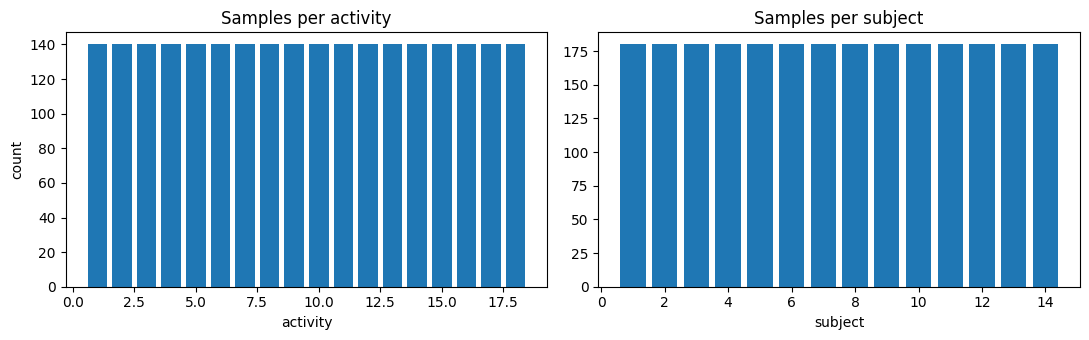

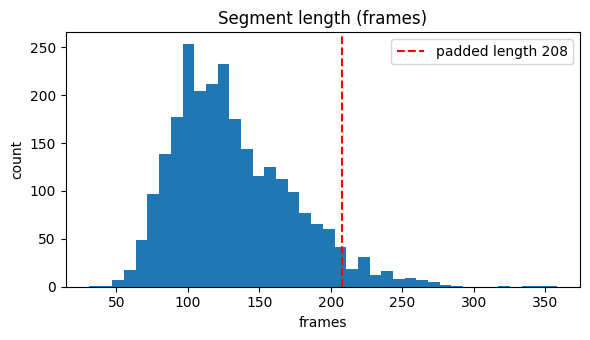

median length 124.0 | truncated: 123


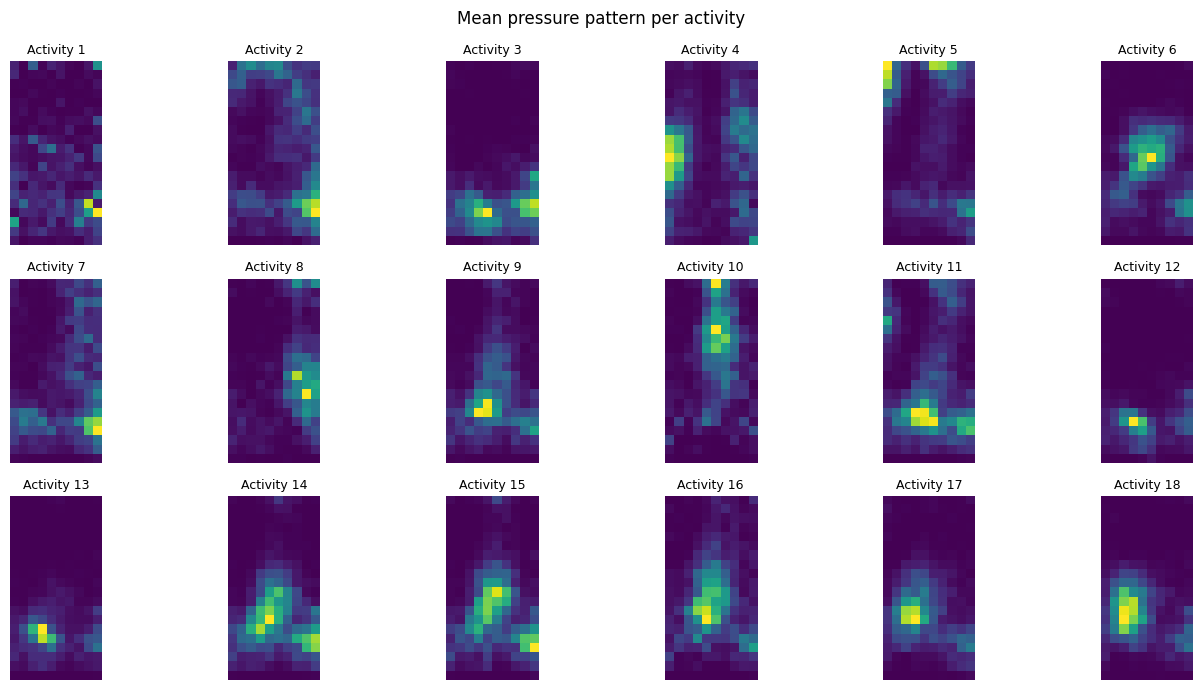

avg change over time: 3.6 | avg pressure: 27.1 | ratio: 0.13


In [ ]:
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
P = Path("data/processed"); F = Path("results/figures"); F.mkdir(parents=True, exist_ok=True)
X = np.load(P/"X.npy"); y = np.load(P/"y.npy"); subj = np.load(P/"subject.npy"); lens = np.load(P/"lengths.npy")
print("X", X.shape, "| pressure min/max:", X.min(), X.max())

# 1. balance of activities and subjects
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(np.arange(1,19), np.bincount(y)); ax[0].set(title="Samples per activity", xlabel="activity", ylabel="count")
ax[1].bar(np.arange(1,15), np.bincount(subj)[1:]); ax[1].set(title="Samples per subject", xlabel="subject")
plt.tight_layout(); plt.savefig(F/"eda_balance.png", dpi=120); plt.show()

# 2. segment lengths
fig, ax = plt.subplots(figsize=(6,3.5))
ax.hist(lens, bins=40); ax.axvline(208, color="r", ls="--", label="padded length 208")
ax.set(title="Segment length (frames)", xlabel="frames", ylabel="count"); ax.legend()
plt.tight_layout(); plt.savefig(F/"eda_lengths.png", dpi=120); plt.show()
print("median length", np.median(lens), "| truncated:", (lens>208).sum())

# 3. average pressure pattern for each activity (20 x 10 sensor grid)
fig, axes = plt.subplots(3, 6, figsize=(14, 7))
for c, ax in enumerate(axes.ravel()):
    m = np.array([X[i,:min(lens[i],208)].mean(axis=0) for i in np.where(y==c)[0]]).mean(axis=0).reshape(20,10)
    ax.imshow(m, cmap="viridis"); ax.set_title(f"Activity {c+1}", fontsize=9); ax.axis("off")
plt.suptitle("Mean pressure pattern per activity")
plt.tight_layout(); plt.savefig(F/"eda_activity_heatmaps.png", dpi=120); plt.show()

# 4. how much does pressure change over time inside a segment?
sd = np.array([X[i,:min(lens[i],208)].astype(float).std(axis=0).mean() for i in range(len(X))])
mp = np.array([X[i,:min(lens[i],208)].astype(float).mean() for i in range(len(X))])
print("avg change over time: %.1f | avg pressure: %.1f | ratio: %.2f" % (sd.mean(), mp.mean(), sd.mean()/mp.mean()))

## Do the label windows line up with real activity?
Total pressure over time for a few trials per activity.

saved results/figures/segment_examples.png


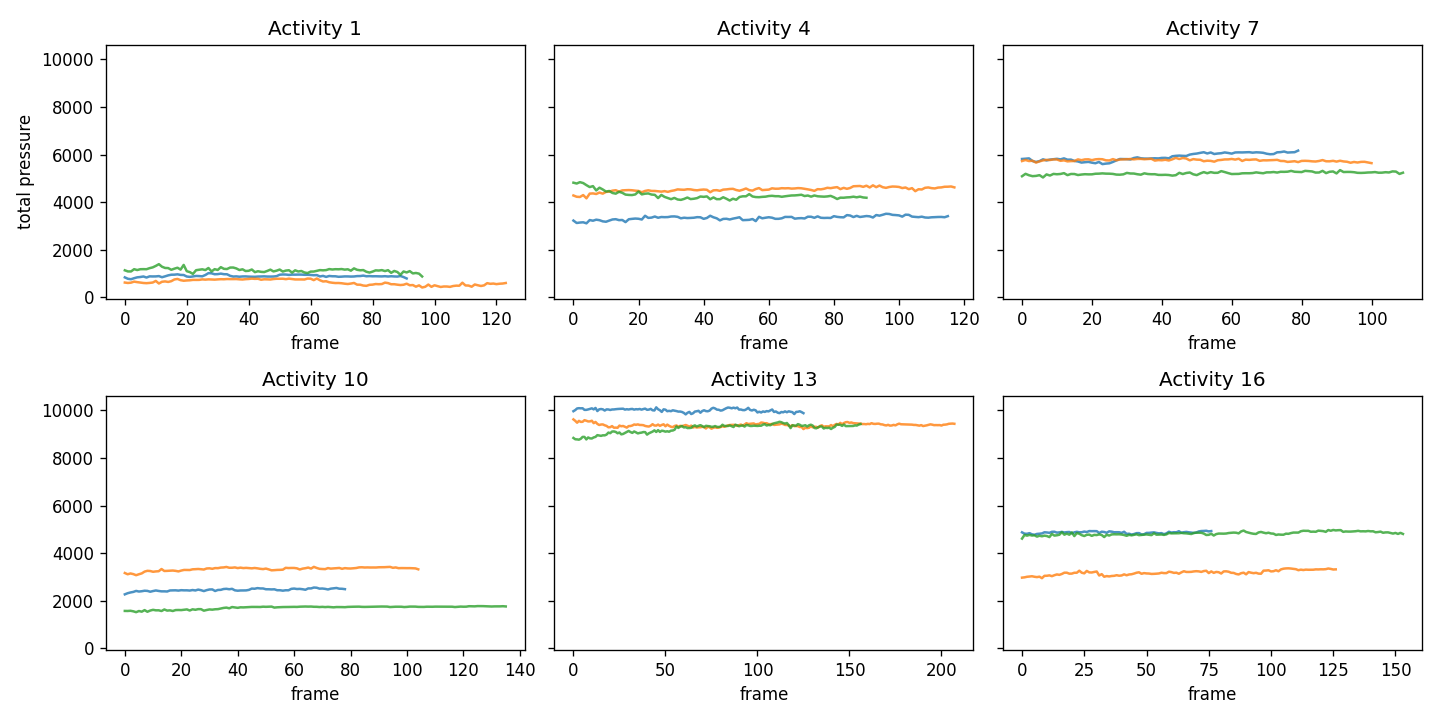

In [ ]:
!python src/sanity_check.py
from IPython.display import Image, display
display(Image('results/figures/segment_examples.png'))

## Self-check and download

In [ ]:
import pandas as pd, numpy as np
from pathlib import Path
sm = pd.read_csv("results/data_quality_summary.csv", index_col=0)["value"]
X = np.load("data/processed/X.npy"); y = np.load("data/processed/y.npy")
checks = {
  "2,520 trials of shape 208 x 200": X.shape == (2520, 208, 200),
  "18 activities, 140 trials each": sorted(set(np.bincount(y))) == [140],
  "no truncated row inside a trial": int(sm["truncated_rows_inside_trials"]) == 0,
  "EDA figures saved": all(Path(f"results/figures/{f}").exists() for f in ["eda_balance.png", "eda_lengths.png", "eda_activity_heatmaps.png", "segment_examples.png"]),
}
for k, v in checks.items(): print("PASS" if v else "FAIL", "-", k)
assert all(checks.values()), "A check failed - read the FAIL lines above"
print("\nNotebook 01 self-check: ALL PASS")

PASS - 2,520 trials of shape 208 x 200
PASS - 18 activities, 140 trials each
PASS - no truncated row inside a trial
PASS - EDA figures saved

Notebook 01 self-check: ALL PASS


In [ ]:
!zip -j results_01.zip results/data_quality_summary.csv results/figures/eda_*.png results/figures/segment_examples.png
from google.colab import files
files.download("results_01.zip")

  adding: data_quality_summary.csv (deflated 55%)
  adding: eda_activity_heatmaps.png (deflated 22%)
  adding: eda_balance.png (deflated 20%)
  adding: eda_lengths.png (deflated 16%)
  adding: segment_examples.png (deflated 9%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>